In [1]:
import pandas as pd
import numpy as np

file_path = "../data/processed/freight_forecasting_features.csv"

df = pd.read_csv(file_path)

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

print("Feature dataset loaded successfully!")
print("Shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Feature dataset loaded successfully!
Shape: (167, 40)
Date range: 2012-01-01 00:00:00 to 2025-11-01 00:00:00


In [2]:
# Naive baseline prediction

df["Naive_Prediction"] = df["Freight_Index"]

print("Naive baseline created!")

print(df[[
    "Date",
    "Freight_Index",
    "Target_Freight_Next_Month",
    "Naive_Prediction"
]].tail(10))

Naive baseline created!
          Date  Freight_Index  Target_Freight_Next_Month  Naive_Prediction
157 2025-02-01            738                     1276.0               738
158 2025-03-01           1276                     1587.0              1276
159 2025-04-01           1587                     1411.0              1587
160 2025-05-01           1411                     1422.0              1411
161 2025-06-01           1422                     1458.0              1422
162 2025-07-01           1458                     2018.0              1458
163 2025-08-01           2018                     2024.0              2018
164 2025-09-01           2024                     1980.0              2024
165 2025-10-01           1980                     1945.0              1980
166 2025-11-01           1945                     2583.0              1945


In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual values
y_true = df["Target_Freight_Next_Month"]

# Naive predictions
y_pred = df["Naive_Prediction"]

# Calculate metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print("Naive Baseline Performance")
print("---------------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

Naive Baseline Performance
---------------------------
MAE : 300.6
RMSE: 432.24
MAPE: 22.59 %


In [4]:
# Moving Average baseline prediction

df["Moving_Average_Prediction"] = df["Freight_Rolling_Mean_3"]

print("Moving Average baseline created!")

print(df[[
    "Date",
    "Freight_Index",
    "Freight_Rolling_Mean_3",
    "Target_Freight_Next_Month",
    "Moving_Average_Prediction"
]].tail(10))

Moving Average baseline created!
          Date  Freight_Index  Freight_Rolling_Mean_3  \
157 2025-02-01            738             1235.000000   
158 2025-03-01           1276             1021.666667   
159 2025-04-01           1587             1014.333333   
160 2025-05-01           1411             1200.333333   
161 2025-06-01           1422             1424.666667   
162 2025-07-01           1458             1473.333333   
163 2025-08-01           2018             1430.333333   
164 2025-09-01           2024             1632.666667   
165 2025-10-01           1980             1833.333333   
166 2025-11-01           1945             2007.333333   

     Target_Freight_Next_Month  Moving_Average_Prediction  
157                     1276.0                1235.000000  
158                     1587.0                1021.666667  
159                     1411.0                1014.333333  
160                     1422.0                1200.333333  
161                     1458.0         

In [5]:
# Moving Average baseline performance

y_true = df["Target_Freight_Next_Month"]
y_pred_ma = df["Moving_Average_Prediction"]

ma_mae = mean_absolute_error(y_true, y_pred_ma)
ma_rmse = np.sqrt(mean_squared_error(y_true, y_pred_ma))
ma_mape = np.mean(np.abs((y_true - y_pred_ma) / y_true)) * 100

print("Moving Average Baseline Performance")
print("------------------------------------")
print("MAE :", round(ma_mae, 2))
print("RMSE:", round(ma_rmse, 2))
print("MAPE:", round(ma_mape, 2), "%")

Moving Average Baseline Performance
------------------------------------
MAE : 430.63
RMSE: 593.3
MAPE: 35.88 %


In [6]:
# Chronological train-test split

test_size = 0.20
split_idx = int(len(df) * (1 - test_size))

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print("Chronological split completed!")
print("--------------------------------")
print("Total rows :", len(df))
print("Training rows:", len(train_df))
print("Testing rows :", len(test_df))

print("\nTraining period:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting period:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

Chronological split completed!
--------------------------------
Total rows : 167
Training rows: 133
Testing rows : 34

Training period:
2012-01-01 00:00:00 to 2023-01-01 00:00:00

Testing period:
2023-02-01 00:00:00 to 2025-11-01 00:00:00


In [7]:
# Select features for XGBoost

feature_cols = [
    # Current freight information
    "Freight_Index",

    # Freight history
    "Freight_Lag_1",
    "Freight_Lag_3",
    "Freight_Lag_6",
    "Freight_Lag_12",
    "Freight_Rolling_Mean_3",
    "Freight_Rolling_Mean_6",
    "Freight_Rolling_Mean_12",

    # Commodity lags
    "Aluminum_Lag_1",
    "Coal, Australian_Lag_1",
    "Coal, South African **_Lag_1",
    "Copper_Lag_1",
    "Crude oil, Brent_Lag_1",
    "Iron ore, cfr spot_Lag_1",
    "Natural gas, Europe_Lag_1",
    "Soybeans_Lag_1",
    "Wheat, US HRW_Lag_1",

    # Trade lags
    "India_Dry_Cargo_Loaded_Lag_1",
    "India_Dry_Cargo_Discharged_Lag_1",

    # Calendar
    "Month",
    "Quarter",
    "Year",

    # Port traffic
    "Chennai_Total_Traffic",
    "Kamarajar_Total_Traffic",
    "Paradip_Total_Traffic",
    "SMP_Kolkata_Haldia_Total_Traffic",
    "Visakhapatnam_Total_Traffic"
]

target_col = "Target_Freight_Next_Month"

print("Number of features:", len(feature_cols))
print("\nFeatures:")
for feature in feature_cols:
    print("-", feature)

Number of features: 27

Features:
- Freight_Index
- Freight_Lag_1
- Freight_Lag_3
- Freight_Lag_6
- Freight_Lag_12
- Freight_Rolling_Mean_3
- Freight_Rolling_Mean_6
- Freight_Rolling_Mean_12
- Aluminum_Lag_1
- Coal, Australian_Lag_1
- Coal, South African **_Lag_1
- Copper_Lag_1
- Crude oil, Brent_Lag_1
- Iron ore, cfr spot_Lag_1
- Natural gas, Europe_Lag_1
- Soybeans_Lag_1
- Wheat, US HRW_Lag_1
- India_Dry_Cargo_Loaded_Lag_1
- India_Dry_Cargo_Discharged_Lag_1
- Month
- Quarter
- Year
- Chennai_Total_Traffic
- Kamarajar_Total_Traffic
- Paradip_Total_Traffic
- SMP_Kolkata_Haldia_Total_Traffic
- Visakhapatnam_Total_Traffic


In [8]:
# Prepare training and testing data

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col]
y_test = test_df[target_col]

print("Training feature shape:", X_train.shape)
print("Testing feature shape :", X_test.shape)

print("\nMissing values in training:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nMissing values in testing:")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

Training feature shape: (133, 27)
Testing feature shape : (34, 27)

Missing values in training:
Chennai_Total_Traffic               22
Kamarajar_Total_Traffic             22
Paradip_Total_Traffic               22
SMP_Kolkata_Haldia_Total_Traffic    22
Visakhapatnam_Total_Traffic         22
dtype: int64

Missing values in testing:
Chennai_Total_Traffic               34
Kamarajar_Total_Traffic             34
Paradip_Total_Traffic               34
SMP_Kolkata_Haldia_Total_Traffic    34
Visakhapatnam_Total_Traffic         34
dtype: int64


In [9]:
# Remove port features because they are unavailable
# throughout the test period

port_features = [
    "Chennai_Total_Traffic",
    "Kamarajar_Total_Traffic",
    "Paradip_Total_Traffic",
    "SMP_Kolkata_Haldia_Total_Traffic",
    "Visakhapatnam_Total_Traffic"
]

model_features = [
    feature for feature in feature_cols
    if feature not in port_features
]

X_train = train_df[model_features].copy()
X_test = test_df[model_features].copy()

y_train = train_df[target_col]
y_test = test_df[target_col]

print("XGBoost features:", len(model_features))
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nRemaining missing values:")
print("Training:", X_train.isna().sum().sum())
print("Testing :", X_test.isna().sum().sum())

XGBoost features: 22
Training shape: (133, 22)
Testing shape : (34, 22)

Remaining missing values:
Training: 0
Testing : 0


In [10]:
from xgboost import XGBRegressor

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

# Train the model
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/isha/Desktop/freight-forecasting-system/ml/venv/lib/python3.13/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <09B43001-8527-34F6-AAE4-B97DA8A6CBC0> /Users/isha/Desktop/freight-forecasting-system/ml/venv/lib/python3.13/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cry

In [11]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [12]:
# Generate predictions for the test data

xgb_predictions = xgb_model.predict(X_test)

print("XGBoost predictions generated successfully!")

comparison = pd.DataFrame({
    "Date": test_df["Date"],
    "Actual": y_test.values,
    "XGBoost_Prediction": xgb_predictions
})

print("\nActual vs XGBoost Prediction:")
print(comparison.head(10))

XGBoost predictions generated successfully!

Actual vs XGBoost Prediction:
          Date  Actual  XGBoost_Prediction
133 2023-02-01  1099.0         1931.290649
134 2023-03-01  1412.0         1212.465820
135 2023-04-01  1552.0         1571.143311
136 2023-05-01   937.0         1515.060547
137 2023-06-01  1068.0          996.656494
138 2023-07-01  1150.0         1169.755005
139 2023-08-01  1065.0         1358.086426
140 2023-09-01  1737.0         1369.267822
141 2023-10-01  1401.0         1705.669922
142 2023-11-01  3192.0         1577.604248


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate XGBoost metrics
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_mape = np.mean(
    np.abs((y_test.values - xgb_predictions) / y_test.values)
) * 100

print("XGBoost Performance on Test Data")
print("--------------------------------")
print("MAE :", round(xgb_mae, 2))
print("RMSE:", round(xgb_rmse, 2))
print("MAPE:", round(xgb_mape, 2), "%")

XGBoost Performance on Test Data
--------------------------------
MAE : 479.8
RMSE: 599.87
MAPE: 32.44 %


In [14]:
# Calculate baseline predictions on the same test data

naive_test_pred = test_df["Freight_Index"].values
moving_average_test_pred = test_df["Freight_Rolling_Mean_3"].values

# Naive metrics
naive_mae = mean_absolute_error(y_test, naive_test_pred)
naive_rmse = np.sqrt(mean_squared_error(y_test, naive_test_pred))
naive_mape = np.mean(
    np.abs((y_test.values - naive_test_pred) / y_test.values)
) * 100

# Moving Average metrics
ma_mae = mean_absolute_error(y_test, moving_average_test_pred)
ma_rmse = np.sqrt(mean_squared_error(y_test, moving_average_test_pred))
ma_mape = np.mean(
    np.abs((y_test.values - moving_average_test_pred) / y_test.values)
) * 100

print("Baseline Performance on Test Data")
print("----------------------------------")

print("\nNaive Model")
print("MAE :", round(naive_mae, 2))
print("RMSE:", round(naive_rmse, 2))
print("MAPE:", round(naive_mape, 2), "%")

print("\nMoving Average Model")
print("MAE :", round(ma_mae, 2))
print("RMSE:", round(ma_rmse, 2))
print("MAPE:", round(ma_mape, 2), "%")

Baseline Performance on Test Data
----------------------------------

Naive Model
MAE : 373.5
RMSE: 522.35
MAPE: 22.84 %

Moving Average Model
MAE : 397.15
RMSE: 531.2
MAPE: 25.74 %


In [15]:
# Final model comparison on the test set

results = pd.DataFrame({
    "Model": ["Naive", "Moving Average", "XGBoost"],
    "MAE": [naive_mae, ma_mae, xgb_mae],
    "RMSE": [naive_rmse, ma_rmse, xgb_rmse],
    "MAPE": [naive_mape, ma_mape, xgb_mape]
})

results = results.round(2)

print("Model Comparison - Test Set")
print("============================")
print(results)

Model Comparison - Test Set
            Model     MAE    RMSE   MAPE
0           Naive  373.50  522.35  22.84
1  Moving Average  397.15  531.20  25.74
2         XGBoost  479.80  599.87  32.44


In [16]:
# Check the chronological structure before walk-forward validation

print("Walk-Forward Validation Setup")
print("=============================")

print("Total observations:", len(df))
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

print("\nTraining period:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting period:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

Walk-Forward Validation Setup
Total observations: 167
First date: 2012-01-01 00:00:00
Last date: 2025-11-01 00:00:00

Training period:
2012-01-01 00:00:00 to 2023-01-01 00:00:00

Testing period:
2023-02-01 00:00:00 to 2025-11-01 00:00:00


In [17]:
# Walk-Forward Validation - Naive Model

walk_forward_actual = []
walk_forward_prediction = []
walk_forward_dates = []

# Start with the original training period
for i in range(len(test_df)):
    
    # Data available up to the current prediction point
    current_train = df.iloc[:split_idx + i]
    
    # Current test observation
    current_test = df.iloc[split_idx + i]
    
    # Naive prediction = most recent known freight index
    prediction = current_train["Freight_Index"].iloc[-1]
    
    walk_forward_actual.append(current_test["Target_Freight_Next_Month"])
    walk_forward_prediction.append(prediction)
    walk_forward_dates.append(current_test["Date"])

# Create results dataframe
walk_forward_results = pd.DataFrame({
    "Date": walk_forward_dates,
    "Actual": walk_forward_actual,
    "Naive_Prediction": walk_forward_prediction
})

print("Walk-Forward Validation completed successfully!")
print("\nFirst 10 predictions:")
print(walk_forward_results.head(10))

Walk-Forward Validation completed successfully!

First 10 predictions:
        Date  Actual  Naive_Prediction
0 2023-02-01  1099.0              1250
1 2023-03-01  1412.0               668
2 2023-04-01  1552.0              1099
3 2023-05-01   937.0              1412
4 2023-06-01  1068.0              1552
5 2023-07-01  1150.0               937
6 2023-08-01  1065.0              1068
7 2023-09-01  1737.0              1150
8 2023-10-01  1401.0              1065
9 2023-11-01  3192.0              1737


In [18]:
# Calculate Walk-Forward Naive Metrics

wf_naive_mae = mean_absolute_error(
    walk_forward_results["Actual"],
    walk_forward_results["Naive_Prediction"]
)

wf_naive_rmse = np.sqrt(mean_squared_error(
    walk_forward_results["Actual"],
    walk_forward_results["Naive_Prediction"]
))

wf_naive_mape = np.mean(
    np.abs(
        (walk_forward_results["Actual"] -
         walk_forward_results["Naive_Prediction"])
        / walk_forward_results["Actual"]
    )
) * 100

print("Walk-Forward Naive Performance")
print("==============================")
print("MAE :", round(wf_naive_mae, 2))
print("RMSE:", round(wf_naive_rmse, 2))
print("MAPE:", round(wf_naive_mape, 2), "%")

Walk-Forward Naive Performance
MAE : 445.88
RMSE: 582.99
MAPE: 29.02 %


In [19]:
# Walk-Forward Validation - XGBoost

wf_xgb_actual = []
wf_xgb_prediction = []
wf_xgb_dates = []

for i in range(len(test_df)):

    # Expanding training data
    current_train = df.iloc[:split_idx + i].copy()

    # Current test observation
    current_test = df.iloc[split_idx + i]

    # Training features and target
    X_wf_train = current_train[model_features]
    y_wf_train = current_train[target_col]

    # Current test features
    X_wf_test = current_test[model_features].to_frame().T

    # Create a fresh XGBoost model
    wf_model = XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    # Train only on data available at that point
    wf_model.fit(X_wf_train, y_wf_train)

    # Predict next month
    prediction = wf_model.predict(X_wf_test)[0]

    wf_xgb_actual.append(current_test[target_col])
    wf_xgb_prediction.append(prediction)
    wf_xgb_dates.append(current_test["Date"])

# Store results
wf_xgb_results = pd.DataFrame({
    "Date": wf_xgb_dates,
    "Actual": wf_xgb_actual,
    "XGBoost_Prediction": wf_xgb_prediction
})

print("Walk-Forward XGBoost validation completed successfully!")
print("\nFirst 10 predictions:")
print(wf_xgb_results.head(10))

ValueError: DataFrame.dtypes for data must be int, float, bool or category. When categorical type is supplied, the experimental DMatrix parameter`enable_categorical` must be set to `True`.  Invalid columns:Freight_Index: object, Freight_Lag_1: object, Freight_Lag_3: object, Freight_Lag_6: object, Freight_Lag_12: object, Freight_Rolling_Mean_3: object, Freight_Rolling_Mean_6: object, Freight_Rolling_Mean_12: object, Aluminum_Lag_1: object, Coal, Australian_Lag_1: object, Coal, South African **_Lag_1: object, Copper_Lag_1: object, Crude oil, Brent_Lag_1: object, Iron ore, cfr spot_Lag_1: object, Natural gas, Europe_Lag_1: object, Soybeans_Lag_1: object, Wheat, US HRW_Lag_1: object, India_Dry_Cargo_Loaded_Lag_1: object, India_Dry_Cargo_Discharged_Lag_1: object, Month: object, Quarter: object, Year: object

In [20]:
# Convert model features to numeric values

for col in model_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check data types
print("Model feature data types:")
print(df[model_features].dtypes)

print("\nRemaining missing values:")
print(df[model_features].isna().sum().sum())

Model feature data types:
Freight_Index                         int64
Freight_Lag_1                       float64
Freight_Lag_3                       float64
Freight_Lag_6                       float64
Freight_Lag_12                      float64
Freight_Rolling_Mean_3              float64
Freight_Rolling_Mean_6              float64
Freight_Rolling_Mean_12             float64
Aluminum_Lag_1                      float64
Coal, Australian_Lag_1              float64
Coal, South African **_Lag_1        float64
Copper_Lag_1                        float64
Crude oil, Brent_Lag_1              float64
Iron ore, cfr spot_Lag_1            float64
Natural gas, Europe_Lag_1           float64
Soybeans_Lag_1                      float64
Wheat, US HRW_Lag_1                 float64
India_Dry_Cargo_Loaded_Lag_1        float64
India_Dry_Cargo_Discharged_Lag_1    float64
Month                                 int64
Quarter                               int64
Year                                  int64
dtype:

In [21]:
# Convert model features to numeric values

for col in model_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Model feature data types:")
print(df[model_features].dtypes)

print("\nRemaining missing values:")
print(df[model_features].isna().sum().sum())

Model feature data types:
Freight_Index                         int64
Freight_Lag_1                       float64
Freight_Lag_3                       float64
Freight_Lag_6                       float64
Freight_Lag_12                      float64
Freight_Rolling_Mean_3              float64
Freight_Rolling_Mean_6              float64
Freight_Rolling_Mean_12             float64
Aluminum_Lag_1                      float64
Coal, Australian_Lag_1              float64
Coal, South African **_Lag_1        float64
Copper_Lag_1                        float64
Crude oil, Brent_Lag_1              float64
Iron ore, cfr spot_Lag_1            float64
Natural gas, Europe_Lag_1           float64
Soybeans_Lag_1                      float64
Wheat, US HRW_Lag_1                 float64
India_Dry_Cargo_Loaded_Lag_1        float64
India_Dry_Cargo_Discharged_Lag_1    float64
Month                                 int64
Quarter                               int64
Year                                  int64
dtype:

In [22]:
wf_xgb_actual = []
wf_xgb_prediction = []
wf_xgb_dates = []

for i in range(len(test_df)):

    current_train = df.iloc[:split_idx + i].copy()
    current_test = df.iloc[split_idx + i]

    X_wf_train = current_train[model_features]
    y_wf_train = current_train[target_col]

    X_wf_test = current_test[model_features].to_frame().T

    wf_model = XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    wf_model.fit(X_wf_train, y_wf_train)

    prediction = wf_model.predict(X_wf_test)[0]

    wf_xgb_actual.append(current_test[target_col])
    wf_xgb_prediction.append(prediction)
    wf_xgb_dates.append(current_test["Date"])


wf_xgb_results = pd.DataFrame({
    "Date": wf_xgb_dates,
    "Actual": wf_xgb_actual,
    "XGBoost_Prediction": wf_xgb_prediction
})

print("Walk-Forward XGBoost validation completed!")
print(wf_xgb_results.head(10))

ValueError: DataFrame.dtypes for data must be int, float, bool or category. When categorical type is supplied, the experimental DMatrix parameter`enable_categorical` must be set to `True`.  Invalid columns:Freight_Index: object, Freight_Lag_1: object, Freight_Lag_3: object, Freight_Lag_6: object, Freight_Lag_12: object, Freight_Rolling_Mean_3: object, Freight_Rolling_Mean_6: object, Freight_Rolling_Mean_12: object, Aluminum_Lag_1: object, Coal, Australian_Lag_1: object, Coal, South African **_Lag_1: object, Copper_Lag_1: object, Crude oil, Brent_Lag_1: object, Iron ore, cfr spot_Lag_1: object, Natural gas, Europe_Lag_1: object, Soybeans_Lag_1: object, Wheat, US HRW_Lag_1: object, India_Dry_Cargo_Loaded_Lag_1: object, India_Dry_Cargo_Discharged_Lag_1: object, Month: object, Quarter: object, Year: object

In [23]:
wf_xgb_actual = []
wf_xgb_prediction = []
wf_xgb_dates = []

for i in range(len(test_df)):

    current_train = df.iloc[:split_idx + i].copy()
    current_test = df.iloc[split_idx + i]

    # Convert training features to numeric
    X_wf_train = current_train[model_features].apply(
        pd.to_numeric, errors="coerce"
    )

    # Convert target to numeric
    y_wf_train = pd.to_numeric(
        current_train[target_col], errors="coerce"
    )

    # Convert test features to numeric
    X_wf_test = current_test[model_features].to_frame().T.apply(
        pd.to_numeric, errors="coerce"
    )

    # Train XGBoost
    wf_model = XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    wf_model.fit(X_wf_train, y_wf_train)

    # Predict
    prediction = wf_model.predict(X_wf_test)[0]

    wf_xgb_actual.append(current_test[target_col])
    wf_xgb_prediction.append(prediction)
    wf_xgb_dates.append(current_test["Date"])


# Create results DataFrame
wf_xgb_results = pd.DataFrame({
    "Date": wf_xgb_dates,
    "Actual": wf_xgb_actual,
    "XGBoost_Prediction": wf_xgb_prediction
})

print("Walk-Forward XGBoost validation completed!")
print()
print(wf_xgb_results.head(10))

Walk-Forward XGBoost validation completed!

        Date  Actual  XGBoost_Prediction
0 2023-02-01  1099.0         1931.290649
1 2023-03-01  1412.0         1150.909424
2 2023-04-01  1552.0         1629.411743
3 2023-05-01   937.0         1495.791504
4 2023-06-01  1068.0          953.203979
5 2023-07-01  1150.0         1140.121826
6 2023-08-01  1065.0         1192.790405
7 2023-09-01  1737.0         1304.273926
8 2023-10-01  1401.0         1697.711914
9 2023-11-01  3192.0         1481.739502


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual and predicted values
actual = wf_xgb_results["Actual"]
predicted = wf_xgb_results["XGBoost_Prediction"]

# Calculate MAE
wf_xgb_mae = mean_absolute_error(actual, predicted)

# Calculate RMSE
wf_xgb_rmse = np.sqrt(mean_squared_error(actual, predicted))

# Calculate MAPE
wf_xgb_mape = np.mean(
    np.abs((actual - predicted) / actual)
) * 100

print("Walk-Forward XGBoost Metrics")
print("============================")
print(f"MAE  : {wf_xgb_mae:.2f}")
print(f"RMSE : {wf_xgb_rmse:.2f}")
print(f"MAPE : {wf_xgb_mape:.2f}%")

Walk-Forward XGBoost Metrics
MAE  : 331.15
RMSE : 462.50
MAPE : 19.89%


In [25]:
# Calculate Walk-Forward Naive metrics

naive_actual = walk_forward_results["Actual"]
naive_predicted = walk_forward_results["Naive_Prediction"]

naive_mae = mean_absolute_error(naive_actual, naive_predicted)
naive_rmse = np.sqrt(mean_squared_error(naive_actual, naive_predicted))
naive_mape = np.mean(
    np.abs((naive_actual - naive_predicted) / naive_actual)
) * 100


# Calculate Walk-Forward Moving Average metrics

ma_actual = test_df["Target_Freight_Next_Month"].values
ma_predicted = test_df["Freight_Rolling_Mean_3"].values

ma_mae = mean_absolute_error(ma_actual, ma_predicted)
ma_rmse = np.sqrt(mean_squared_error(ma_actual, ma_predicted))
ma_mape = np.mean(
    np.abs((ma_actual - ma_predicted) / ma_actual)
) * 100


# Display comparison

print("Walk-Forward Model Comparison")
print("=============================")

print("\nNaive Baseline")
print(f"MAE  : {naive_mae:.2f}")
print(f"RMSE : {naive_rmse:.2f}")
print(f"MAPE : {naive_mape:.2f}%")

print("\nMoving Average")
print(f"MAE  : {ma_mae:.2f}")
print(f"RMSE : {ma_rmse:.2f}")
print(f"MAPE : {ma_mape:.2f}%")

print("\nXGBoost")
print(f"MAE  : {wf_xgb_mae:.2f}")
print(f"RMSE : {wf_xgb_rmse:.2f}")
print(f"MAPE : {wf_xgb_mape:.2f}%")

Walk-Forward Model Comparison

Naive Baseline
MAE  : 445.88
RMSE : 582.99
MAPE : 29.02%

Moving Average
MAE  : 397.15
RMSE : 531.20
MAPE : 25.74%

XGBoost
MAE  : 331.15
RMSE : 462.50
MAPE : 19.89%


In [26]:
evaluation_results = pd.DataFrame({
    "Model": [
        "Naive",
        "Moving Average",
        "XGBoost"
    ],
    "MAE": [
        naive_mae,
        ma_mae,
        wf_xgb_mae
    ],
    "RMSE": [
        naive_rmse,
        ma_rmse,
        wf_xgb_rmse
    ],
    "MAPE (%)": [
        naive_mape,
        ma_mape,
        wf_xgb_mape
    ]
})

evaluation_results = evaluation_results.round(2)

print("Final Model Evaluation")
print("======================")
print(evaluation_results)

Final Model Evaluation
            Model     MAE    RMSE  MAPE (%)
0           Naive  445.88  582.99     29.02
1  Moving Average  397.15  531.20     25.74
2         XGBoost  331.15  462.50     19.89


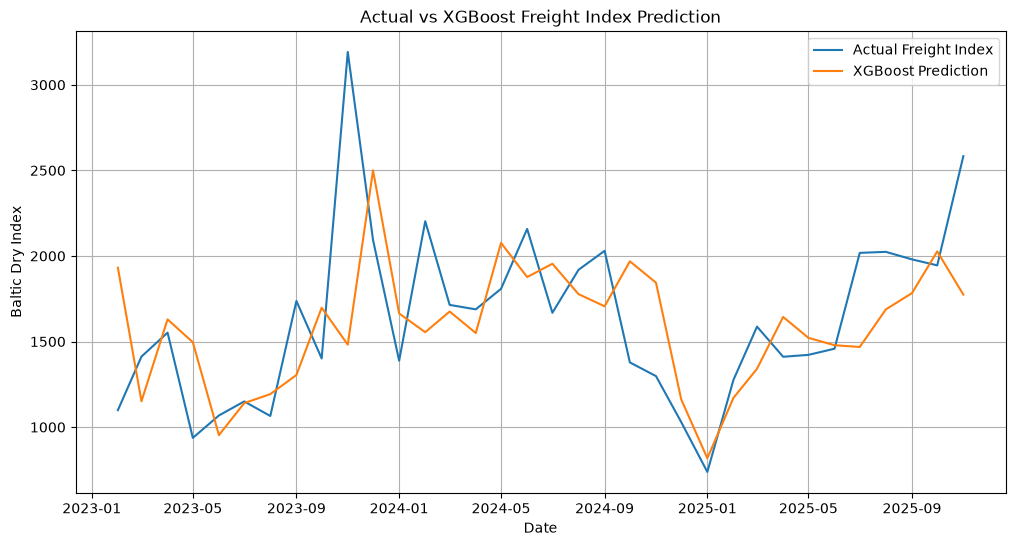

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    wf_xgb_results["Date"],
    wf_xgb_results["Actual"],
    label="Actual Freight Index"
)

plt.plot(
    wf_xgb_results["Date"],
    wf_xgb_results["XGBoost_Prediction"],
    label="XGBoost Prediction"
)

plt.title("Actual vs XGBoost Freight Index Prediction")
plt.xlabel("Date")
plt.ylabel("Baltic Dry Index")
plt.legend()
plt.grid(True)

plt.show()

In [28]:
# Calculate prediction errors

wf_xgb_results["Error"] = (
    wf_xgb_results["Actual"]
    - wf_xgb_results["XGBoost_Prediction"]
)

wf_xgb_results["Absolute_Error"] = (
    wf_xgb_results["Error"].abs()
)

print("Prediction Error Analysis")
print("=========================")

print(
    wf_xgb_results[
        ["Date", "Actual", "XGBoost_Prediction", "Error", "Absolute_Error"]
    ].head(10)
)

Prediction Error Analysis
        Date  Actual  XGBoost_Prediction        Error  Absolute_Error
0 2023-02-01  1099.0         1931.290649  -832.290649      832.290649
1 2023-03-01  1412.0         1150.909424   261.090576      261.090576
2 2023-04-01  1552.0         1629.411743   -77.411743       77.411743
3 2023-05-01   937.0         1495.791504  -558.791504      558.791504
4 2023-06-01  1068.0          953.203979   114.796021      114.796021
5 2023-07-01  1150.0         1140.121826     9.878174        9.878174
6 2023-08-01  1065.0         1192.790405  -127.790405      127.790405
7 2023-09-01  1737.0         1304.273926   432.726074      432.726074
8 2023-10-01  1401.0         1697.711914  -296.711914      296.711914
9 2023-11-01  3192.0         1481.739502  1710.260498     1710.260498


In [29]:
# Calculate uncertainty from walk-forward prediction errors

lower_error = np.percentile(
    wf_xgb_results["Error"],
    5
)

upper_error = np.percentile(
    wf_xgb_results["Error"],
    95
)

print("Prediction Error Range")
print("======================")
print(f"5th percentile error  : {lower_error:.2f}")
print(f"95th percentile error : {upper_error:.2f}")

Prediction Error Range
5th percentile error  : -569.97
95th percentile error : 704.62


In [30]:
# Create 90% prediction interval

wf_xgb_results["Lower_Bound"] = (
    wf_xgb_results["XGBoost_Prediction"] + lower_error
)

wf_xgb_results["Upper_Bound"] = (
    wf_xgb_results["XGBoost_Prediction"] + upper_error
)

# Check whether actual value falls inside the interval
wf_xgb_results["Inside_Interval"] = (
    (wf_xgb_results["Actual"] >= wf_xgb_results["Lower_Bound"]) &
    (wf_xgb_results["Actual"] <= wf_xgb_results["Upper_Bound"])
)

# Calculate coverage
coverage = (
    wf_xgb_results["Inside_Interval"].mean() * 100
)

print("90% Prediction Interval")
print("=======================")

print(f"Lower error : {lower_error:.2f}")
print(f"Upper error : {upper_error:.2f}")
print(f"Observed coverage : {coverage:.2f}%")

print("\nSample predictions:")
print(
    wf_xgb_results[
        [
            "Date",
            "Actual",
            "XGBoost_Prediction",
            "Lower_Bound",
            "Upper_Bound"
        ]
    ].head(10)
)

90% Prediction Interval
Lower error : -569.97
Upper error : 704.62
Observed coverage : 88.24%

Sample predictions:
        Date  Actual  XGBoost_Prediction  Lower_Bound  Upper_Bound
0 2023-02-01  1099.0         1931.290649  1361.324951  2635.910400
1 2023-03-01  1412.0         1150.909424   580.943787  1855.529297
2 2023-04-01  1552.0         1629.411743  1059.446045  2334.031494
3 2023-05-01   937.0         1495.791504   925.825867  2200.411377
4 2023-06-01  1068.0          953.203979   383.238342  1657.823730
5 2023-07-01  1150.0         1140.121826   570.156189  1844.741699
6 2023-08-01  1065.0         1192.790405   622.824768  1897.410156
7 2023-09-01  1737.0         1304.273926   734.308289  2008.893799
8 2023-10-01  1401.0         1697.711914  1127.746338  2402.331787
9 2023-11-01  3192.0         1481.739502   911.773865  2186.359375


In [31]:
# Phase 14: Trend Detection

# Calculate percentage change in freight index
wf_xgb_results["Percentage_Change"] = (
    wf_xgb_results["XGBoost_Prediction"].pct_change() * 100
)

# Classify trend
def classify_trend(change):
    if change > 5:
        return "Rising"
    elif change < -5:
        return "Falling"
    else:
        return "Stable"

wf_xgb_results["Trend"] = (
    wf_xgb_results["Percentage_Change"]
    .apply(classify_trend)
)

print("Trend Detection")
print("================")

print(
    wf_xgb_results[
        [
            "Date",
            "XGBoost_Prediction",
            "Percentage_Change",
            "Trend"
        ]
    ].head(15)
)

Trend Detection
         Date  XGBoost_Prediction  Percentage_Change    Trend
0  2023-02-01         1931.290649                NaN   Stable
1  2023-03-01         1150.909424         -40.407242  Falling
2  2023-04-01         1629.411743          41.576015   Rising
3  2023-05-01         1495.791504          -8.200521  Falling
4  2023-06-01          953.203979         -36.274273  Falling
5  2023-07-01         1140.121826          19.609428   Rising
6  2023-08-01         1192.790405           4.619563   Stable
7  2023-09-01         1304.273926           9.346449   Rising
8  2023-10-01         1697.711914          30.165291   Rising
9  2023-11-01         1481.739502         -12.721384  Falling
10 2023-12-01         2499.988281          68.719826   Rising
11 2024-01-01         1663.992432         -33.439987  Falling
12 2024-02-01         1554.576904          -6.575483  Falling
13 2024-03-01         1675.405640           7.772446   Rising
14 2024-04-01         1549.684814          -7.503903  

In [32]:
# Count trend categories

trend_counts = wf_xgb_results["Trend"].value_counts()

print("Trend Distribution")
print("===================")
print(trend_counts)

print("\nTrend Percentages")
print("=================")

trend_percentages = (
    wf_xgb_results["Trend"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(trend_percentages)

Trend Distribution
Trend
Falling    14
Rising     14
Stable      6
Name: count, dtype: int64

Trend Percentages
Trend
Falling    41.18
Rising     41.18
Stable     17.65
Name: proportion, dtype: float64


In [33]:
# Phase 15: Volatility Analysis

# Calculate month-to-month percentage change
wf_xgb_results["Monthly_Change"] = (
    wf_xgb_results["XGBoost_Prediction"].pct_change() * 100
)

# Calculate volatility as the standard deviation
volatility = wf_xgb_results["Monthly_Change"].std()

print("Volatility Analysis")
print("===================")
print(f"Monthly volatility : {volatility:.2f}%")

Volatility Analysis
Monthly volatility : 24.51%


In [34]:
# Classify overall volatility

if volatility < 10:
    volatility_level = "Low"
elif volatility < 20:
    volatility_level = "Moderate"
else:
    volatility_level = "High"

print("Volatility Classification")
print("=========================")
print(f"Monthly volatility : {volatility:.2f}%")
print(f"Volatility level   : {volatility_level}")

Volatility Classification
Monthly volatility : 24.51%
Volatility level   : High


In [35]:
# Phase 16: SHAP Explainability

import shap
import matplotlib.pyplot as plt

# Train one final XGBoost model on the training portion
final_xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

X_train_final = train_df[model_features].apply(
    pd.to_numeric,
    errors="coerce"
)

y_train_final = train_df[target_col].apply(
    pd.to_numeric,
    errors="coerce"
)

final_xgb_model.fit(
    X_train_final,
    y_train_final
)

# Prepare test data
X_test_final = test_df[model_features].apply(
    pd.to_numeric,
    errors="coerce"
)

# Create SHAP explainer
explainer = shap.TreeExplainer(final_xgb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_final)

print("SHAP analysis completed!")
print("Test samples:", X_test_final.shape[0])
print("Features:", X_test_final.shape[1])
print("SHAP values shape:", shap_values.shape)

/Users/isha/Desktop/freight-forecasting-system/ml/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP analysis completed!
Test samples: 34
Features: 22
SHAP values shape: (34, 22)


In [36]:
# Calculate average SHAP importance for each feature

shap_importance = pd.DataFrame({
    "Feature": model_features,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

# Sort from most important to least important
shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("SHAP Feature Importance")
print("=======================")
print(shap_importance)

SHAP Feature Importance
                             Feature  Mean_Absolute_SHAP
0                       Copper_Lag_1          382.395752
1                      Freight_Index          166.634247
2                     Aluminum_Lag_1           91.379173
3                              Month           61.157730
4           Iron ore, cfr spot_Lag_1           49.443474
5            Freight_Rolling_Mean_12           35.055557
6                      Freight_Lag_1           29.575809
7                      Freight_Lag_6           24.860331
8                     Freight_Lag_12           21.155033
9             Coal, Australian_Lag_1           20.921741
10                     Freight_Lag_3           19.556345
11      India_Dry_Cargo_Loaded_Lag_1           19.262615
12            Freight_Rolling_Mean_6           15.390312
13            Crude oil, Brent_Lag_1           12.593704
14            Freight_Rolling_Mean_3           10.429876
15                              Year            9.376213
16     

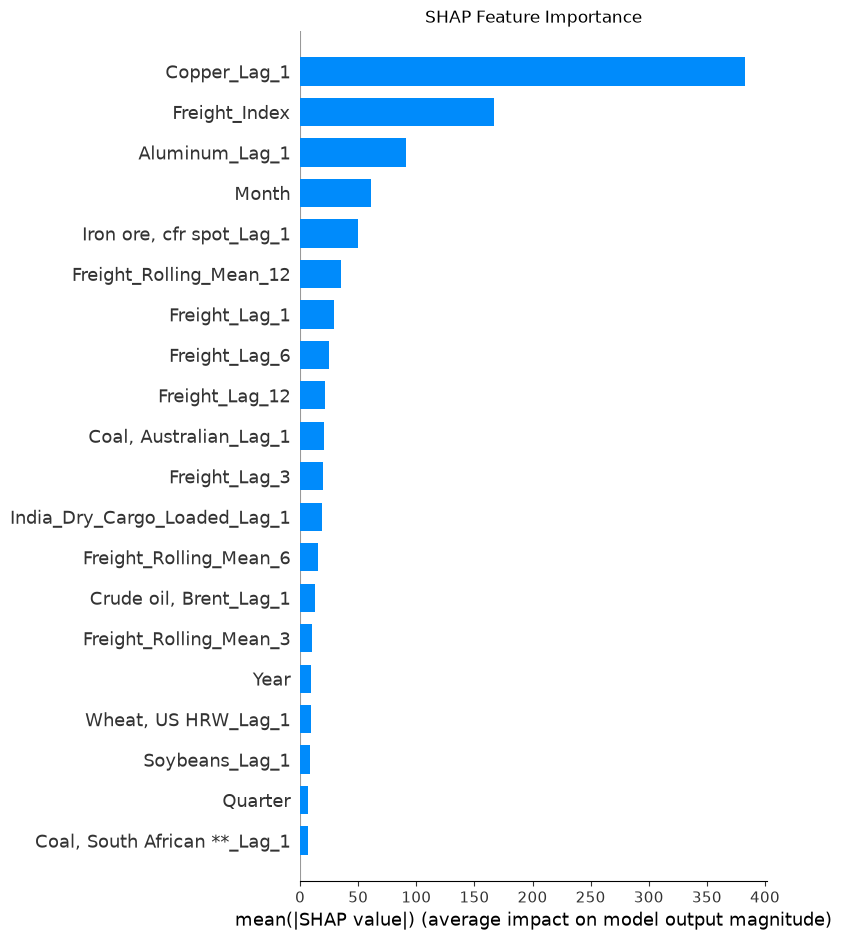

In [37]:
# SHAP Feature Importance Plot

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_test_final,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance")
plt.tight_layout()
plt.show()

In [38]:
# Phase 17: Save XGBoost Model

import joblib
import os

# Create models folder if it doesn't exist
model_dir = "../models"
os.makedirs(model_dir, exist_ok=True)

# Model version
model_version = "xgboost_v1.0"

# Model file path
model_path = os.path.join(
    model_dir,
    f"{model_version}.joblib"
)

# Save model
joblib.dump(
    final_xgb_model,
    model_path
)

print("Model saved successfully!")
print(f"Model version : {model_version}")
print(f"Model path    : {model_path}")

Model saved successfully!
Model version : xgboost_v1.0
Model path    : ../models/xgboost_v1.0.joblib


In [39]:
# Phase 17B: Save Model Metadata

import json

metadata = {
    "model_version": "xgboost_v1.0",
    "model_type": "XGBoost Regressor",
    "target": "Target_Freight_Next_Month",
    "forecast_target": "Baltic Dry Index",
    "forecast_horizon": "1 month",
    "features": model_features,
    "training_start": str(train_df["Date"].min().date()),
    "training_end": str(train_df["Date"].max().date()),
    "test_start": str(test_df["Date"].min().date()),
    "test_end": str(test_df["Date"].max().date()),
    "metrics": {
        "MAE": 331.15,
        "RMSE": 462.50,
        "MAPE": 19.89
    }
}

metadata_path = "../models/xgboost_v1.0_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Model metadata saved successfully!")
print(f"Metadata path : {metadata_path}")

Model metadata saved successfully!
Metadata path : ../models/xgboost_v1.0_metadata.json


In [40]:
# Phase 18A: Load Saved Model

import joblib

# Path to saved model
model_path = "../models/xgboost_v1.0.joblib"

# Load the model
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Model loaded successfully!
Model type: XGBRegressor


In [41]:
# Phase 18B: Generate Prediction Using Loaded Model

# Use the latest available feature row
latest_row = df.iloc[[-1]]

# Prepare the input features
X_latest = latest_row[model_features].apply(
    pd.to_numeric,
    errors="coerce"
)

# Generate prediction
next_month_prediction = loaded_model.predict(X_latest)[0]

print("Next-Month Freight Forecast")
print("==========================")
print(f"Current Freight Index : {latest_row['Freight_Index'].iloc[0]:.2f}")
print(f"Forecast              : {next_month_prediction:.2f}")

Next-Month Freight Forecast
Current Freight Index : 1945.00
Forecast              : 2359.66


In [44]:
# Phase 18C: Final Prediction Output

forecast = next_month_prediction

# Prediction interval
lower_bound = forecast + lower_error
upper_bound = forecast + upper_error

# Current forecast trend
current_rate = float(latest_row["Freight_Index"].iloc[0])
forecast_change = ((forecast - current_rate) / current_rate) * 100

if forecast_change > 5:
    latest_trend = "Rising"
elif forecast_change < -5:
    latest_trend = "Falling"
else:
    latest_trend = "Stable"

# Previously calculated volatility
latest_volatility = volatility

# Create final prediction output
prediction_output = {
    "current_rate": current_rate,
    "forecast_rate": float(forecast),
    "trend": latest_trend,
    "volatility": f"{latest_volatility:.2f}%",
    "confidence": "Medium",
    "lower_bound": float(lower_bound),
    "upper_bound": float(upper_bound),
    "forecast_horizon": "1 month",
    "model": "XGBoost",
    "model_version": "xgboost_v1.0",
    "explanation": (
        f"Forecast is {forecast_change:.2f}% higher than the current "
        f"Baltic Dry Index. The model predicts a Rising trend."
    )
}

print("Freight Forecast Output")
print("=======================")

for key, value in prediction_output.items():
    print(f"{key}: {value}")

Freight Forecast Output
current_rate: 1945.0
forecast_rate: 2359.66259765625
trend: Rising
volatility: 24.51%
confidence: Medium
lower_bound: 1789.6969421386718
upper_bound: 3064.2824401855464
forecast_horizon: 1 month
model: XGBoost
model_version: xgboost_v1.0
explanation: Forecast is 21.32% higher than the current Baltic Dry Index. The model predicts a Rising trend.


In [43]:
# Fix trend for the current forecast

current_rate = float(latest_row["Freight_Index"].iloc[0])
forecast_rate = float(next_month_prediction)

forecast_change = (
    (forecast_rate - current_rate) / current_rate
) * 100

if forecast_change > 5:
    forecast_trend = "Rising"
elif forecast_change < -5:
    forecast_trend = "Falling"
else:
    forecast_trend = "Stable"

print("Current Forecast Trend")
print("======================")
print(f"Current rate    : {current_rate:.2f}")
print(f"Forecast rate   : {forecast_rate:.2f}")
print(f"Expected change : {forecast_change:.2f}%")
print(f"Trend           : {forecast_trend}")

Current Forecast Trend
Current rate    : 1945.00
Forecast rate   : 2359.66
Expected change : 21.32%
Trend           : Rising


In [45]:
# Phase 19A: Model Loading Test

import joblib
import os

model_path = "../models/xgboost_v1.0.joblib"

print("Checking model file...")

if os.path.exists(model_path):
    print("Model file found!")
    
    test_model = joblib.load(model_path)
    
    print("Model loaded successfully!")
    print("Model type:", type(test_model).__name__)
else:
    print("ERROR: Model file not found!")

Checking model file...
Model file found!
Model loaded successfully!
Model type: XGBRegressor


In [46]:
# Phase 19B: Prediction Test

# Use the latest available feature row
test_row = df.iloc[[-1]]

# Select the same features used during training
X_test_prediction = test_row[model_features].apply(
    pd.to_numeric,
    errors="coerce"
)

# Generate prediction using the loaded model
test_prediction = test_model.predict(X_test_prediction)[0]

print("Prediction test completed!")
print(f"Current Freight Index : {test_row['Freight_Index'].iloc[0]:.2f}")
print(f"Predicted Next Month  : {test_prediction:.2f}")

Prediction test completed!
Current Freight Index : 1945.00
Predicted Next Month  : 2359.66


In [47]:
# Phase 19C: Prediction Output Validation

required_fields = [
    "current_rate",
    "forecast_rate",
    "trend",
    "volatility",
    "confidence",
    "lower_bound",
    "upper_bound",
    "forecast_horizon",
    "model",
    "model_version",
    "explanation"
]

print("Checking required fields...")

missing_fields = [
    field for field in required_fields
    if field not in prediction_output
]

if missing_fields:
    print("FAILED!")
    print("Missing fields:", missing_fields)
else:
    print("All required fields are present!")

# Validate numerical values
checks_passed = True

if prediction_output["current_rate"] <= 0:
    print("FAILED: Current rate is not positive")
    checks_passed = False

if prediction_output["forecast_rate"] <= 0:
    print("FAILED: Forecast rate is not positive")
    checks_passed = False

if prediction_output["lower_bound"] > prediction_output["forecast_rate"]:
    print("FAILED: Lower bound is greater than forecast")
    checks_passed = False

if prediction_output["upper_bound"] < prediction_output["forecast_rate"]:
    print("FAILED: Upper bound is smaller than forecast")
    checks_passed = False

if checks_passed:
    print("All prediction value checks passed!")

Checking required fields...
All required fields are present!
All prediction value checks passed!


In [48]:
# Phase 19D: Prediction Consistency Test

# Load the model again
reloaded_model = joblib.load("../models/xgboost_v1.0.joblib")

# Generate prediction again
reloaded_prediction = reloaded_model.predict(X_test_prediction)[0]

# Compare with the previous prediction
difference = abs(test_prediction - reloaded_prediction)

print("Prediction consistency test")
print("===========================")
print(f"Original prediction : {test_prediction:.6f}")
print(f"Reloaded prediction : {reloaded_prediction:.6f}")
print(f"Difference          : {difference:.10f}")

if difference < 0.000001:
    print("Consistency test PASSED!")
else:
    print("Consistency test FAILED!")

Prediction consistency test
Original prediction : 2359.662598
Reloaded prediction : 2359.662598
Difference          : 0.0000000000
Consistency test PASSED!


In [49]:
# Phase 19E: Check Walk-Forward Predictions

predictions = wf_xgb_results["XGBoost_Prediction"]

print("Checking walk-forward predictions...")
print("Number of predictions:", len(predictions))

invalid_predictions = (
    predictions.isna().sum()
    + (~np.isfinite(predictions)).sum()
    + (predictions < 0).sum()
)

print("Invalid predictions:", invalid_predictions)

if invalid_predictions == 0:
    print("Final prediction validity test PASSED!")
else:
    print("Final prediction validity test FAILED!")

Checking walk-forward predictions...
Number of predictions: 34
Invalid predictions: 0
Final prediction validity test PASSED!
